# 🧪 LAB: Classifying IoT Device Types with Machine Learning

**Motivation**: The rapid expansion of the Internet of Things (IoT) has dramatically increased the number and diversity of devices connected to modern networks. While these devices bring convenience and functionality, they also introduce new security vulnerabilities. In particular, the presence of unauthorized or malicious IoT devices within a network can pose a serious threat to organizational infrastructure.

To mitigate this risk, it is critical to develop tools that can automatically identify the type of IoT devices connected to a network based on their network traffic behavior. In this lab, you will explore this challenge by building and comparing machine learning models that classify IoT devices by type using real-world network data. 

To this end, in this lab you will be evaluating the effectiveness of different ensemble methods and reflecting on their performance. You will also compare these methods with neural network models.

**Dataset Description**: To do this lab, you will be working with a dataset that contains network traffic features collected from various Internet of Things (IoT) devices operating in a simulated smart home environment. The goal is to automatically identify the type of IoT device connected to the network based on its traffic behavior.

Problem Type: Multi-class classification — identifying which device type (e.g., camera, thermostat) corresponds to a given network traffic sample.

- Instances: 1,800 network traffic captures.

- Features: ~297 attributes per instance, including packet-level and flow-level statistics, protocol usage patterns, temporal and size-based features, categorical indicators (e.g., protocol types)

- Target Variable: device_category — class label indicating the type of IoT device (e.g., 'Light', 'Camera', 'Thermostat', etc.)

---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.


NAME(s) = "Laine Goldmacher, Max Magrill, Ashley Qin"

## Part 1: Data Preparation and Visualization (15 points)

In this part, you will prepare the data for modeling and explore it using dimensionality reduction techniques.

You should do the following:

1. **Load the data**  
   Load `iot_devices_train.csv` as the training dataset and `iot_devices_reporting.csv` as the reporting dataset.

2. **Separate inputs and outcomes**  
   - The outcome variable corresponds to the `"device_category"` column.  
   - Separate this column from the input features.

3. **Encode the outcome variable**  
   - The outcome variable (type of device) is currently a text variable.  
   - Convert it into numeric values so that each device type is assigned a unique number. Make sure device types are encoded correctly and consistently across the training and reporting sets.
   - *Hint:* You can use `LabelEncoder` from `scikit-learn` for this task.

4. **Dimensionality reduction for visualization**  
   - Apply both PCA and UMAP to reduce the dimensionality of the training set to two dimensions.  
   - Before applying PCA or UMAP, standardize the features. **IMPORTANT:** This standardization is only for the dimensionality reduction visualizations.  
   - Use **pipelines** to apply standardization followed by each dimensionality reduction method.

5. **Visualize the results**  
   - Create two scatter plots (one for PCA, one for UMAP) showing the 2D representations.  
   - Color each point according to its IoT device label.

6. **Compare the methods**  
   - Briefly discuss the differences between the PCA and UMAP visualizations.  
   - What patterns or separations can you observe? Which method seems to give better information about the structure in the data?


In [60]:
import pandas as pd
import numpy as np

In [61]:
#1
data_train = pd.read_csv("iot_devices_train.csv")
data_reporting = pd.read_csv("iot_devices_reporting.csv")
data_train.head()

,ack,ack_A,ack_B,bytes,bytes_A,bytes_A_B_ratio,bytes_B,ds_field_A,ds_field_B,duration,...,suffix_is_co.il,suffix_is_com,suffix_is_com.sg,suffix_is_else,suffix_is_empty_char_value,suffix_is_googleapis.com,suffix_is_net,suffix_is_org,suffix_is_unresolved,device_category
0,9,5,5,1213,743,0.713924,668,0,0,1.5756,...,0,0,0,1,0,0,0,0,0,security_camera
1,9,5,5,1213,743,1.806874,668,0,0,0.6890,...,0,0,0,1,0,0,0,0,0,security_camera
2,9,5,5,1213,743,0.103124,668,0,0,0.9852,...,0,0,0,1,0,0,0,0,0,security_camera
3,9,5,5,1213,743,1.806874,668,0,0,1.5756,...,0,0,0,1,0,0,0,0,0,security_camera
4,9,5,5,1213,743,1.806874,668,0,0,1.5756,...,0,0,0,1,0,0,0,0,0,security_camera


In [62]:
#2
y_train = data_train['device_category']
y_reporting = data_reporting['device_category']

x_train = data_train.drop(['device_category'], axis=1)
x_reporting = data_reporting.drop(['device_category'], axis=1)
x_train.head()

,ack,ack_A,ack_B,bytes,bytes_A,bytes_A_B_ratio,bytes_B,ds_field_A,ds_field_B,duration,...,suffix_is_cloudfront.net,suffix_is_co.il,suffix_is_com,suffix_is_com.sg,suffix_is_else,suffix_is_empty_char_value,suffix_is_googleapis.com,suffix_is_net,suffix_is_org,suffix_is_unresolved
0,9,5,5,1213,743,0.713924,668,0,0,1.5756,...,0,0,0,0,1,0,0,0,0,0
1,9,5,5,1213,743,1.806874,668,0,0,0.6890,...,0,0,0,0,1,0,0,0,0,0
2,9,5,5,1213,743,0.103124,668,0,0,0.9852,...,0,0,0,0,1,0,0,0,0,0
3,9,5,5,1213,743,1.806874,668,0,0,1.5756,...,0,0,0,0,1,0,0,0,0,0
4,9,5,5,1213,743,1.806874,668,0,0,1.5756,...,0,0,0,0,1,0,0,0,0,0


In [63]:
#3
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_reporting_encoded = le.transform(y_reporting)

y_reporting_encoded[:10]

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1])

In [64]:
#4
from sklearn.decomposition import PCA
from umap import UMAP
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

pipeline_steps_pca = [
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=2))
]

pipeline_steps_umap = [
    ('scaler', StandardScaler()),
    ('pca', UMAP(n_components=2))
]

pipe_pca = Pipeline(steps=pipeline_steps_pca)
pipe_umap = Pipeline(steps=pipeline_steps_umap)

pca_data = pipe_pca.fit_transform(x_train, y_train_encoded)
umap_data = pipe_umap.fit_transform(x_train, y_train_encoded)


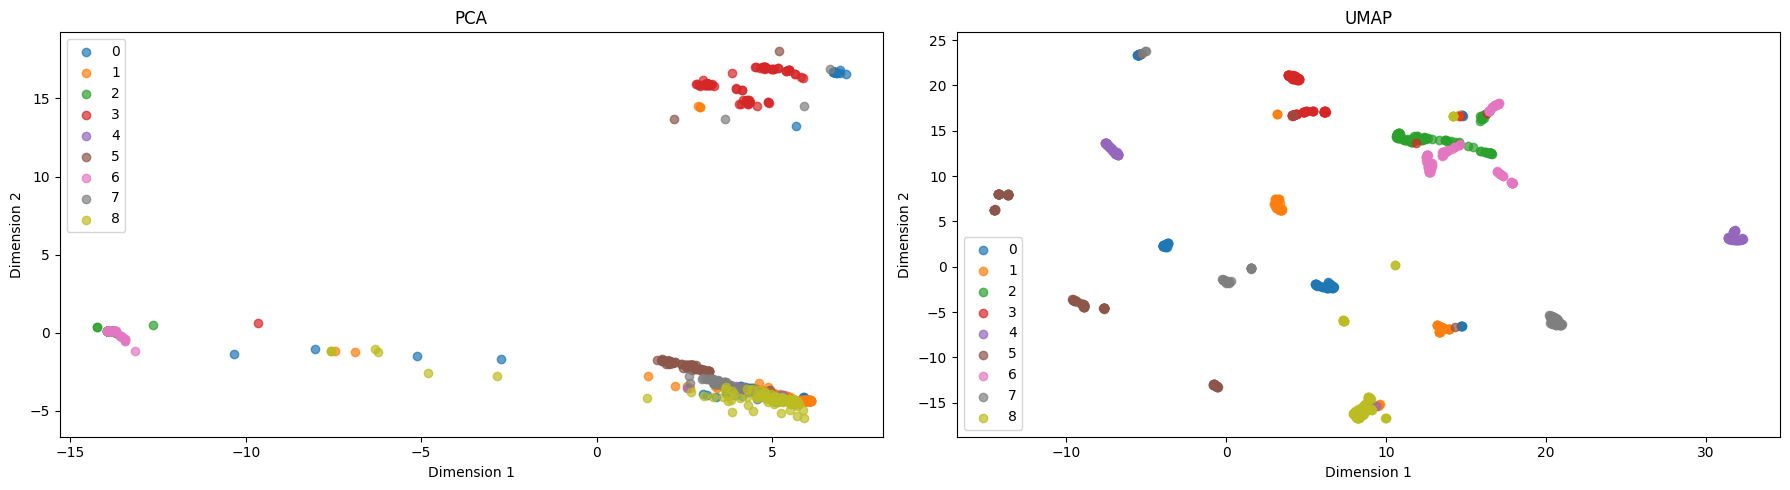

In [65]:
#5
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(18, 5))

projections = [np.asarray(pca_data), np.asarray(umap_data)]
titles = ['PCA', 'UMAP']
labels = np.asarray(y_train_encoded).ravel()

for ax, projection, title in zip(axes, projections, titles):
    for i in np.unique(labels):
        mask = labels == i
        ax.scatter(projection[mask, 0], projection[mask, 1], label=i, alpha=0.7)

    ax.set_title(title)
    ax.set_xlabel('Dimension 1')
    ax.set_ylabel('Dimension 2')
    ax.legend()

plt.tight_layout()
plt.show()

#5. **Visualize the results**  
 #  - Create two scatter plots (one for PCA, one for UMAP) showing the 2D representations.  
 #  - Color each point according to its IoT device label.

6. Discussion

UMAP produced more distinct clusters with less overlap between device categories, whereas PCA showed more overlapping groups. This may be because PCA preserves directions of maximum variance through a linear projection, while UMAP uses a nonlinear approach designed to preserve local structure. Overall, UMAP appeared more effective at visualizing separation between device types in this dataset.

## Part 2: Ensemble Methods with Scikit-Learn (40 points)

In this part, you will compare the performance of **Gradient Boosting** and **Random Forests** on the IoT device classification dataset.

Your tasks are:

1. **Pre-analysis Discussion and reflection**  
  Before starting, think about whether the typical preprocessing steps in machine learning (e.g., scaling, normalization, encoding) are necessary for tree-based ensemble methods such as Random Forests and Gradient Boosting. Write a brief explanation of which preprocessing steps (if any) you believe are required for these methods and why, and apply them only if you consider them necessary.

3. **Optimize each model**  
   Train and optimize both models using different combinations of the following hyperparameters:

   - Gradient Boosting: `max_depth`, `learning_rate`  
   - Random Forest: `max_depth`, `max_features`  

   *Tip:* Check the documentation of each model to understand what values make sense for these parameters.

   To ensure a fair comparison:
   - Use the same cross-validation object when optimizing both models.  
   - Use the same candidate values for `max_depth` across models.  
   - To keep the runtime manageable, test only THREE different values for each hyperparameter.  
   - Use a 5-fold cross-validation for tuning.

4. **Evaluate performance**  
   - Use each optimized model to evaluate performance on the reporting data.  
   - Report the accuracy and confusion matrix.
   - Report the total fitting time for the hyperparameter search. To measure it, record the time right before fitting the method and again immediately after it finishes. You can record the time using the `time()` function from the Python package `time`. Then, calculate the difference between the two to obtain the total training time (in minutes).
   - Discuss which types of devices are predicted most accurately and which are more difficult to classify.

5. **Analyze feature importance**  
   - Compare the feature importance resulting from each model. Do this both qualitatively and quantitatively (for example, by examining the similarity between feature importance vectors).
   - Are the most important features consistent across models? Which ones are these? Please, keep this discussion concise but thoughtful—focus on patterns and possible explanations rather than just listing numbers.
    
6. **Reflection**:  How do you think the models performed compared to random guessing?  *Hint:* A baseline accuracy of 50% assumes uniform random guessing between two categories. Since this is a multi-class problem, how should that baseline change?

1. For these tree-based ensemble models, Random Forests and Gradient Boosting, we do not need to standardize or normalize the data. Unlike distance-based models, decision trees split observations based on feature thresholds rather than magnitudes of distances between observations. Therefore, changing the scale of numerical features generally does not affect performance. However, categorical features must be encoded numerically because scikit-learn's standard implementations of these models require numerical inputs. For steps in preprocessing, we will split the data into training and reporting sets, and divide them into the data set and target set (X and Y). We will also encode the output to match the numeric dataset. These steps have already been completed in part 1.

In [66]:
#2
from time import time
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, confusion_matrix

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

gb_params = {
    "max_depth": [3, 5, 7],
    "learning_rate": [0.01, 0.1, 0.2]
}

rf_params = {
    "max_depth": [3, 5, 7],
    "max_features": ["sqrt", "log2", None]
}

gb = GradientBoostingClassifier(random_state=42)
rf = RandomForestClassifier(random_state=42)

gb_search = GridSearchCV(gb, gb_params, cv=cv, scoring="accuracy", n_jobs=-1)

rf_search = GridSearchCV(rf, rf_params, cv=cv, scoring="accuracy", n_jobs=-1)

start = time()
gb_search.fit(x_train, y_train)
gb_time = (time() - start) / 60

start = time()
rf_search.fit(x_train, y_train)
rf_time = (time() - start) / 60

print("Gradient Boosting best parameters:", gb_search.best_params_)
print("Gradient Boosting CV accuracy:", gb_search.best_score_)
print("Gradient Boosting fitting time (min):", gb_time)

print("Random Forest best parameters:", rf_search.best_params_)
print("Random Forest CV accuracy:", rf_search.best_score_)
print("Random Forest fitting time (min):", rf_time)

Gradient Boosting best parameters: {'learning_rate': 0.1, 'max_depth': 3}
Gradient Boosting CV accuracy: 0.8899999999999999
Gradient Boosting fitting time (min): 0.6926312804222107
Random Forest best parameters: {'max_depth': 7, 'max_features': 'sqrt'}
Random Forest CV accuracy: 0.8788888888888889
Random Forest fitting time (min): 0.026458799839019775


Gradient Boosting achieved a slightly higher cross-validation accuracy of 89.00% than Random Forest's 87.89%, suggesting that it performed marginally better during model optimization.

In [67]:
#3
gb_pred = gb_search.best_estimator_.predict(x_reporting)
rf_pred = rf_search.best_estimator_.predict(x_reporting)

print("Gradient Boosting Accuracy:", accuracy_score(y_reporting, gb_pred))

print("Gradient Boosting Confusion Matrix:")
print(confusion_matrix(y_reporting, gb_pred))

print("\nRandom Forest Accuracy:", accuracy_score(y_reporting, rf_pred))

print("Random Forest Confusion Matrix:")
print(confusion_matrix(y_reporting, rf_pred))

Gradient Boosting Accuracy: 0.6788888888888889
Gradient Boosting Confusion Matrix:
[[ 78   2   0   0   2   0   0   0  18]
 [ 13  74   0   0   1   0   0  12   0]
 [  0   0  49   0   0   0  51   0   0]
 [ 19   0   0  54   0   0   0   8  19]
 [  0   0   0   4  34   0   0  30  32]
 [  0   0   0   0   0 100   0   0   0]
 [  0   0  22   1   0   0  77   0   0]
 [  6   0   0   0   0   0   2  92   0]
 [ 44   1   0   0   0   0   0   2  53]]

Random Forest Accuracy: 0.6422222222222222
Random Forest Confusion Matrix:
[[ 51   4   1   0   1   0   0   0  43]
 [ 13  86   0   0   0   0   0   1   0]
 [  0   0  56   0   0   0  44   0   0]
 [ 25   0   0  65   0   0   0   2   8]
 [  0   0   0  34  34   0   0   0  32]
 [  0   0   0   0   0 100   0   0   0]
 [  0   0  22   0   0   0  78   0   0]
 [ 61   0   0   0   2   0   0  37   0]
 [ 27   0   0   0   0   0   0   2  71]]


The optimized Gradient Boosting model achieved a reporting accuracy of 67.89%, while Random Forest achieved 64.22%. Gradient Boosting therefore outperformed Random Forest by approximately 3.67 percentage points.

The total fitting time for Gradient Boosting's hyperparameter search was 0.6934 minutes (41.60 seconds), compared to 0.0268 minutes (1.61 seconds) for Random Forest. Random Forest was therefore approximately 26 times faster to optimize, although Gradient Boosting achieved higher accuracy.

Based on the confusion matrices, device category 5 was classified perfectly by both models, achieving 100% accuracy. Gradient Boosting also performed particularly well on category 7 (92%), whereas Random Forest performed well on category 1 (86%). Category 4 was the most difficult for both models, achieving only 34% accuracy. Both models frequently confused categories 2 and 6, suggesting that these devices may share similar network traffic characteristics. There was also considerable confusion between categories 0 and 8.

Both models experienced a substantial decrease in accuracy between cross-validation and reporting, suggesting potential differences between the training and reporting datasets or limitations in how well the models generalize to unseen data.

In [68]:
#4
feature_names = x_train.columns

gb_importance = gb_search.best_estimator_.feature_importances_
rf_importance = rf_search.best_estimator_.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Gradient Boosting": gb_importance,
    "Random Forest": rf_importance
})

importance_df = importance_df.sort_values(
    "Gradient Boosting",
    ascending=False
)

display(importance_df)

correlation = np.corrcoef(gb_importance, rf_importance)[0, 1]

print("Feature importance correlation:", correlation)

gb_top5 = set(importance_df.nlargest(5, "Gradient Boosting")["Feature"])
rf_top5 = set(importance_df.nlargest(5, "Random Forest")["Feature"])

print("Common top 5 features:", gb_top5 & rf_top5)

,Feature,Gradient Boosting,Random Forest
230,ttl_avg,0.098787,0.022574
101,packet_inter_arrivel_B_min,0.057259,0.013199
111,packet_inter_arrivel_min,0.056624,0.012442
113,packet_inter_arrivel_sum,0.054734,0.020256
93,packet_inter_arrivel_A_sum,0.054288,0.020507
...,...,...,...
183,ssl_ratio_server_name,0.000000,0.000000
184,ssl_req_bytes_avg,0.000000,0.000000
185,ssl_req_bytes_entropy,0.000000,0.000000
186,ssl_req_bytes_firstQ,0.000000,0.000000


Feature importance correlation: 0.5508935066111325
Common top 5 features: set()


In [69]:
gb_importance = gb_search.best_estimator_.feature_importances_
rf_importance = rf_search.best_estimator_.feature_importances_

importance_df = pd.DataFrame({
    "Feature": x_train.columns,
    "Gradient Boosting": gb_importance,
    "Random Forest": rf_importance
})

display(importance_df.sort_values("Gradient Boosting", ascending=False).head(10))

correlation = np.corrcoef(gb_importance, rf_importance)[0, 1]
print(f"Feature importance correlation: {correlation:.4f}")

gb_top5 = set(importance_df.nlargest(5, "Gradient Boosting")["Feature"])
rf_top5 = set(importance_df.nlargest(5, "Random Forest")["Feature"])

print("Gradient Boosting top 5:", gb_top5)
print("Random Forest top 5:", rf_top5)
print("Features in both top 5:", gb_top5 & rf_top5)

,Feature,Gradient Boosting,Random Forest
230,ttl_avg,0.098787,0.022574
101,packet_inter_arrivel_B_min,0.057259,0.013199
111,packet_inter_arrivel_min,0.056624,0.012442
113,packet_inter_arrivel_sum,0.054734,0.020256
93,packet_inter_arrivel_A_sum,0.054288,0.020507
108,packet_inter_arrivel_firstQ,0.053005,0.011143
231,ttl_entropy,0.050830,0.016851
235,ttl_min,0.045276,0.036785
76,http_time_avg,0.040649,0.001383
94,packet_inter_arrivel_A_thirdQ,0.036755,0.007962


Feature importance correlation: 0.5509
Gradient Boosting top 5: {'ttl_avg', 'packet_inter_arrivel_B_min', 'packet_inter_arrivel_A_sum', 'packet_inter_arrivel_min', 'packet_inter_arrivel_sum'}
Random Forest top 5: {'ttl_max', 'ttl_B_avg', 'ttl_B_max', 'ttl_B_min', 'ttl_min'}
Features in both top 5: set()


In [70]:
importance_df.nlargest(5, "Random Forest")[["Feature", "Random Forest"]]

,Feature,Random Forest
225,ttl_B_min,0.049394
223,ttl_B_max,0.038866
235,ttl_min,0.036785
220,ttl_B_avg,0.033105
233,ttl_max,0.027906


Gradient Boosting and Random Forest showed moderate similarity in their feature importance scores, with a Pearson correlation of 0.551. Although none of their top five individual features overlapped, both models emphasized time-to-live (TTL) characteristics.

Gradient Boosting's most important features included ttl_avg and several packet inter-arrival time measures, such as packet_inter_arrivel_B_min, packet_inter_arrivel_min, packet_inter_arrivel_sum, and packet_inter_arrivel_A_sum. In contrast, Random Forest's top five features were all related to TTL, including ttl_B_min, ttl_B_max, ttl_min, ttl_B_avg, and ttl_max.

This suggests that both models rely on network packet characteristics to distinguish IoT device types, but Gradient Boosting places greater emphasis on packet timing, while Random Forest relies more heavily on TTL measurements. These differences may arise because Gradient Boosting builds trees sequentially to correct previous errors, whereas Random Forest combines independently trained trees. Overall, the models identify similar types of important information but prioritize different individual features.

6. 
Because this dataset contains nine IoT device categories, the expected accuracy of uniform random guessing is approximately 11.11% (1/9), rather than the 50% baseline associated with binary classification.

Both Gradient Boosting (67.89%) and Random Forest (64.22%) substantially outperformed this baseline. Gradient Boosting achieved approximately 6.1 times the accuracy of uniform random guessing, while Random Forest achieved approximately 5.8 times that accuracy. This indicates that both models successfully learned meaningful relationships between network traffic features and device categories. Although Gradient Boosting demonstrated slightly stronger predictive performance, Random Forest was significantly faster to optimize. Overall, both ensemble methods performed much better than random guessing, with a tradeoff between predictive accuracy and computational efficiency.

## Part 3: Histogram-Based Gradient Boosting (20 points)

Gradient Boosting is a powerful algorithm, but it can also be computationally expensive. To address this limitation, a modern and optimized implementation inspired by *LightGBM* has been introduced (see recommended reading). In `scikit-learn`, this approach is available through `HistGradientBoostingClassifier`.

Here, you will explore how this implementation differs from the traditional `GradientBoostingClassifier`, understand the mechanisms behind its computational efficiency, and apply it to the same dataset used previously.

You should complete the following steps:

1. **Read and summarize**  
   Read the [Histogram-based Gradient Boosting documentation](https://scikit-learn.org/stable/modules/ensemble.html#histogram-based-gradient-boosting), which describes the algorithm and its key differences from `GradientBoostingClassifier`.  

   *Optional (for deeper understanding):*
   - Ke et al. (2017). *[LightGBM: A Highly Efficient Gradient Boosting Decision Tree](https://proceedings.neurips.cc/paper_files/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html)*  
   - *[Introduction to Boosted Trees — XGBoost documentation](https://xgboost.readthedocs.io/en/stable/tutorials/model.html)*  

   Then, briefly answer the following questions:  
   - What are the main differences between `HistGradientBoostingClassifier` and `GradientBoostingClassifier`?  
   - How does histogram binning make training faster?

2. **Optimize and train a `HistGradientBoostingClassifier` object from `sklearn.ensemble`**  
   - Use the same approach you applied to Gradient Boosting in Part 2.  
   - Reuse the same `param_grid` from Part 2.  
   - Use `GridSearchCV` for hyperparameter tuning.  
   - Use the same cross-validation object to ensure a fair comparison.

3. **Evaluate the optimized model**  
   - Report the accuracy and confusion matrix.
   - Measure and report the total hyperparameter search time, following the same procedure used in Part 2.
4. **Reflection**  
   - How does this method compare to `GradientBoostingClassifier` in terms of computation time and predictive performance? Discuss any trade-offs you observe.

In [71]:
# USE AS MANY CELLS AS NEEDED

## Part 4: Neural Network Model (20 points)

In this final part of the assignment, you will revisit neural networks and compare their performance with the ensemble methods explored in the previous parts.

You should do the following:

1. **Preprocessing reflection**  
   - Briefly describe which preprocessing steps are important before training a neural network.  
   - If such steps are necessary in this case, apply them before training your model.

2. **Model optimization and training**  
   - Use NINE different combinations of hidden units and hidden layers as the hyperparameters to tune.
   - Use early stopping to reduce the risk of overfitting.  
   - Train the model for up to 300 epochs.  
   - Use `GridSearchCV` to optimize the model’s hyperparameters.  
   - Make sure to use the same cross-validation object as in Parts 2 and 3 for a fair comparison.  
   - *Tip:* Check the [MLPClassifier documentation](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html) to see how to enable early stopping and adjust other parameters.

3. **Evaluate performance**  
   - Use the same evaluation metrics as in Parts 2 and 3.  
   - Compare the neural network’s performance with the ensemble models.  
   - Reflect on how model complexity and interpretability differ across methods.

**Constraint:**  
Use `MLPClassifier` from `scikit-learn` for this exercise.


In [72]:
# USE AS MANY CELLS AS NEEDED

## Part 5: Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

YOUR TEXT HERE